# Proyek Klasifikasi Gambar: Fruit classification(10 Class)
- **Nama:** Samuel Sahat Mardyantoro
- **Email:** muelsahat@gmail.com
- **ID Dicoding:** samuel_sahatt

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image
from tensorflow.keras.preprocessing import image_dataset_from_directory
import os
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import shutil
import random
from tensorflow.keras.applications import EfficientNetB0
from pathlib import Path
from tensorflow.keras.callbacks import ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from glob import glob
from tensorflow.keras.models import Sequential
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Conv2D, Flatten, MaxPooling2D
import seaborn as sns
from pathlib import Path

## Data Preparation

### Data Loading

In [2]:
base_dir = r"C:\Users\asus\Downloads\archive (9)"
subdirs = ['train', 'test', 'predict']

Membaca gambar dari folder dataset dan menyusunnya dalam bentuk DataFrame

In [3]:
all_images = []
for subdir in subdirs:
    folder = os.path.join(base_dir, subdir)
    for class_name in os.listdir(folder):
        class_path = os.path.join(folder, class_name)
        if os.path.isdir(class_path):
            for file in glob(os.path.join(class_path, '*.*')):
                if file.lower().endswith(('png', 'jpg', 'jpeg')):
                    all_images.append((file, class_name))

# Buat DataFrame
df = pd.DataFrame(all_images, columns=['filepath', 'label'])
print(f"Total gambar yang ditemukan: {len(df)}")
print(df['label'].value_counts())

Total gambar yang ditemukan: 3326
label
mango           336
avocado         335
cherry          335
kiwi            335
pinenapple      335
watermelon      335
orange          327
Apple           230
Banana          230
strawberries    230
banana          106
stawberries     103
apple            89
Name: count, dtype: int64


### Data Preprocessing

Merubah penulisan label agar menjadi sama 

In [4]:
label_map = {
    'apple': 'apple',
    'Apple': 'apple',
    'banana': 'banana',
    'Banana': 'banana',
    'strawberries': 'strawberries',
    'stawberries': 'strawberries',
    'pinenapple': 'pineapple' 
}

df['label'] = df['label'].str.lower().replace(label_map)

print(df['label'].value_counts())


label
banana          336
mango           336
avocado         335
cherry          335
kiwi            335
pineapple       335
watermelon      335
strawberries    333
orange          327
apple           319
Name: count, dtype: int64


#### Split Dataset

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df['label'], random_state=42)
valid_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42)

print(f"Train : {len(train_df)}")
print(f"Valid : {len(valid_df)}")
print(f"Test  : {len(test_df)}")
print(train_df.columns)


Train : 2328
Valid : 499
Test  : 499
Index(['filepath', 'label'], dtype='object')


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

Membuat Data Generator yang akan digunakan dalam modelling

In [6]:
datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    class_mode='categorical',
    batch_size=32,
    shuffle=True
)

val_generator = datagen.flow_from_dataframe(
    dataframe=valid_df,
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

test_generator = datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)
num_classes = len(train_generator.class_indices)

Found 2328 validated image filenames belonging to 10 classes.
Found 499 validated image filenames belonging to 10 classes.
Found 499 validated image filenames belonging to 10 classes.


## Modelling

Menggunakan model transfer learning InceptionV3

In [ ]:
# Inisialisasi base model InceptionV3
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False 

In [32]:
# Bangun model transfer learning
model = Sequential([
    base_model,
    Conv2D(64, (3,3), activation='relu'),    
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')        
])

In [33]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_301 (Conv2D)             │ (None, 3, 3, 64)       │     1,179,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 1, 1, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,992,106 (87.71 MB)

 Trainable params: 1,189,322 (4.54 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

Proses training dengan callback checkpoint dan earlystop

In [35]:
# Callbacks
checkpoint = ModelCheckpoint("best_model_inceptionv3.h5", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
earlystop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

# Training model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=[checkpoint, earlystop]
)

Epoch 1/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 1.0000 - loss: 3.6743e-04
Epoch 1: val_accuracy improved from -inf to 0.88577, saving model to best_model_inceptionv3.h5


73/73 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 1.0000 - loss: 3.6742e-04 - val_accuracy: 0.8858 - val_loss: 0.5502
Epoch 2/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 1.0000 - loss: 3.0859e-04
Epoch 2: val_accuracy did not improve from 0.88577
73/73 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 1.0000 - loss: 3.0884e-04 - val_accuracy: 0.8858 - val_loss: 0.5541
Epoch 3/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 1.0000 - loss: 3.2777e-04
Epoch 3: val_accuracy did not improve from 0.88577
73/73 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 1.0000 - loss: 3.2736e-04 - val_accuracy: 0.8858 - val_loss: 0.5556
Epoch 4/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 1.0000 - loss: 2.7344e-04
Epoch 4: val_accuracy did not improve from 0.88577
73/73 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 1.0000 - loss: 2.7337e-04 - val_accuracy: 0.8858 - val_loss: 0.5621
Epoch 5/50
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 1.0000 - loss: 2.2900e-04
Epoch 5: val_accura

## Evaluasi dan Visualisasi

Melakukan pengujian model dengan dataset test

In [36]:
test_loss, test_acc = model.evaluate(test_generator, verbose=2)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

16/16 - 27s - 2s/step - accuracy: 0.8597 - loss: 0.6763
Test loss: 0.6763418912887573
Test accuracy: 0.859719455242157


Visualisasi prediksi klasifikasi 10 buah

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


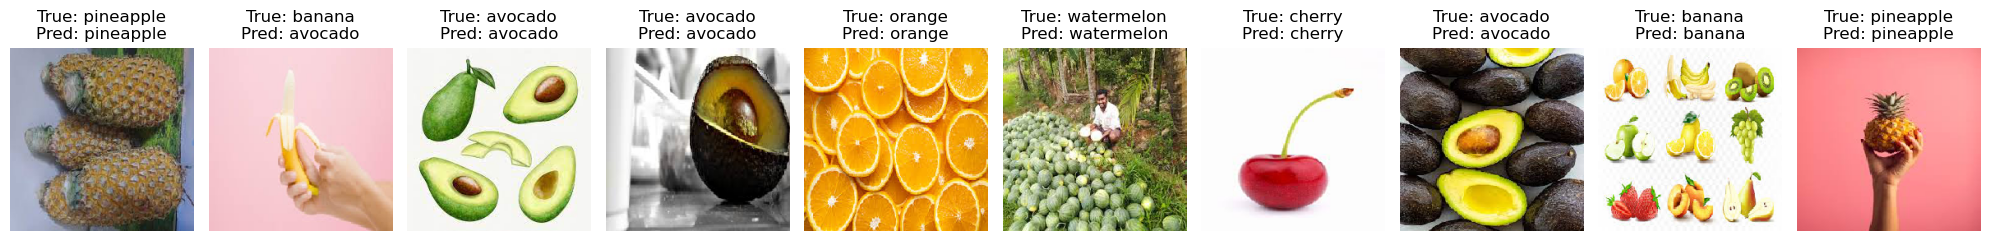

In [37]:
test_generator.reset()
x_test, y_test = next(test_generator)

pred_probs = model.predict(x_test)
pred_labels = np.argmax(pred_probs, axis=1)
true_labels = np.argmax(y_test, axis=1)

class_labels = list(test_generator.class_indices.keys())

plt.figure(figsize=(20, 20))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(x_test[i])
    plt.axis('off')
    plt.title(f"True: {class_labels[true_labels[i]]}\nPred: {class_labels[pred_labels[i]]}")
plt.tight_layout()

Grafik akurasi dan loss

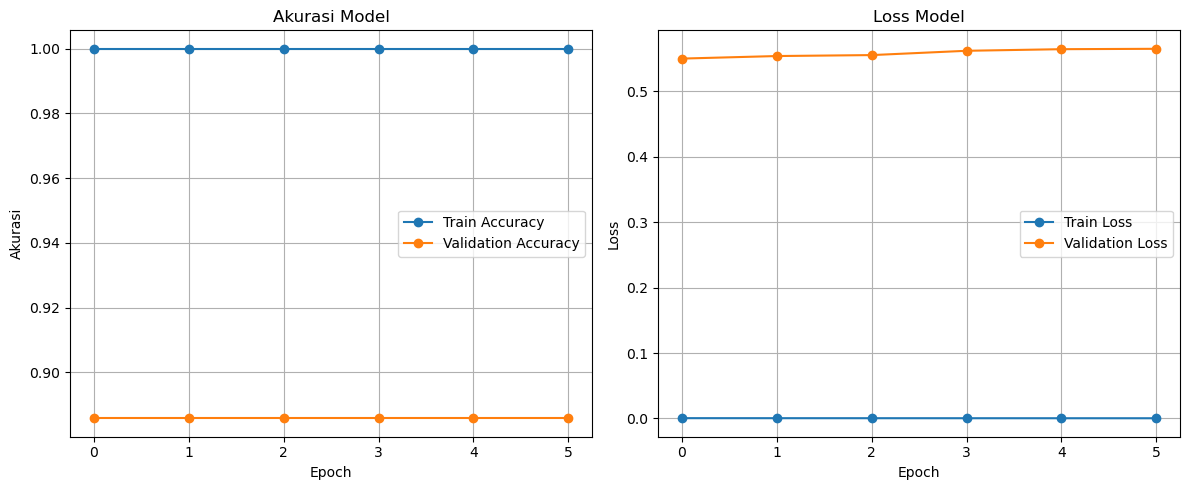

In [38]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Akurasi Model')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Loss Model')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Classification report dari model

In [39]:
test_generator.reset()

# 
pred_probs = model.predict(test_generator)
pred_classes = np.argmax(pred_probs, axis=1)

true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

report = classification_report(true_classes, pred_classes, target_names=class_labels)
print("Classification Report:\n")
print(report)

16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step
Classification Report:

              precision    recall  f1-score   support

       apple       0.92      0.92      0.92        48
     avocado       0.88      0.82      0.85        51
      banana       0.92      0.88      0.90        50
      cherry       0.93      0.86      0.90        50
        kiwi       0.78      0.86      0.82        50
       mango       0.69      0.80      0.75        51
      orange       0.82      0.76      0.79        49
   pineapple       0.98      0.90      0.94        50
strawberries       0.96      0.94      0.95        50
  watermelon       0.78      0.86      0.82        50

    accuracy                           0.86       499
   macro avg       0.87      0.86      0.86       499
weighted avg       0.87      0.86      0.86       499



Confusion Matrix

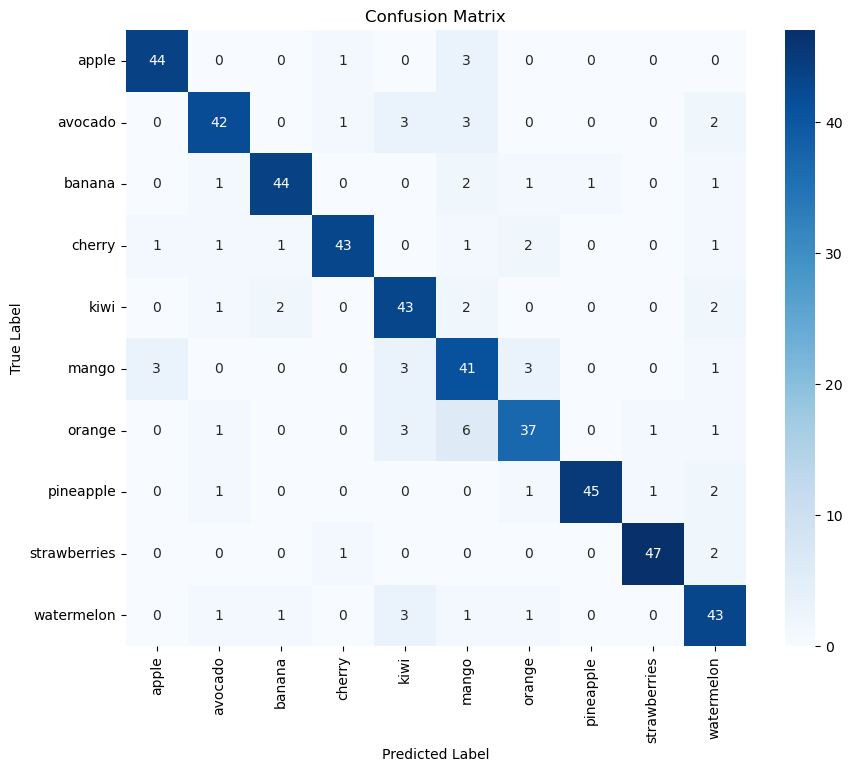

In [40]:
cm = confusion_matrix(true_classes, pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## Konversi Model

Export model dalam format saved_model

In [41]:
downloads_path = Path.home() / "Downloads"    
model_path = downloads_path / "saved_model"  

os.makedirs(model_path, exist_ok=True)

print(f"Saving model to: {model_path}")
model.export(model_path)

Saving model to: C:\Users\asus\Downloads\saved_model
INFO:tensorflow:Assets written to: C:\Users\asus\Downloads\saved_model\assets


INFO:tensorflow:Assets written to: C:\Users\asus\Downloads\saved_model\assets


Saved artifact at 'C:\Users\asus\Downloads\saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_1018')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  2788161380880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161382416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161384528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161384720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161386064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161384912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161386448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161386640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161387600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2788161381840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  278816138

Convert saved_model menjadi format tflite

In [43]:
saved_model_dir = "C:/Users/asus/Downloads/saved_model"

converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
tflite_model = converter.convert()

tflite_model_path = "C:/Users/asus/Downloads/tflite/model.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print("Model TFLite disimpan di:", tflite_model_path)

Model TFLite disimpan di: C:/Users/asus/Downloads/tflite/model.tflite


In [44]:
class_names = list(train_generator.class_indices.keys())
print(class_names)

with open("label.txt", "w") as f:
    for label in class_names:
        f.write(label + "\n")

['apple', 'avocado', 'banana', 'cherry', 'kiwi', 'mango', 'orange', 'pineapple', 'strawberries', 'watermelon']


In [45]:
with open("C:/Users/asus/Downloads/tflite/label.txt", "w") as f:
    for label in class_names:
        f.write(label + "\n")

Mengconvert format saved_model menjadi tfjs

dilakukan dalam file colab terpisah karena projek dikerjakan dalam local file

In [ ]:
# !tensorflowjs_converter --input_format=tf_saved_model "/content/drive/MyDrive/saved_model" "/content/drive/MyDrive/tfjs_model"
# https://colab.research.google.com/drive/1h3ODolmHss9nUpvgRbWYPnOCWpr5-kUa?usp=sharing

Membuat file requirements

In [46]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


Model berhasil mencapai akurasi validasi tertinggi sebesar 88.58% pada epoch pertama, sebelum akhirnya dihentikan lebih awal karena tidak ada peningkatan selama beberapa epoch berikutnya. Pada test data, model mempertahankan kinerja yang baik dengan akurasi sebesar 85.97% dan loss 0.676, menunjukkan bahwa model cukup generalisasi terhadap data yang belum pernah dilihat.

Dari hasil metrik klasifikasi, sebagian besar kelas buah memiliki nilai precision, recall, dan f1-score di atas 0.85, terutama kelas seperti pineapple, strawberries, apple, dan cherry. Namun, terdapat beberapa kelas seperti mango, kiwi, dan watermelon yang masih menunjukkan performa relatif lebih rendah, dengan f1-score di kisaran 0.75–0.82. Hal ini menunjukkan bahwa model kesulitan membedakan beberapa kelas tertentu, kemungkinan disebabkan oleh kemiripan visual antar kelas, ketidakseimbangan jumlah data, atau variasi pencahayaan dan sudut gambar.

## Inference (Optional)